TechBazaar: E-commerce Sales Data Cleaning & EDA

Importing Libraries

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sea

Importing Data

In [63]:
customer=pd.read_csv("messy_customers.csv")
order_items=pd.read_csv("messy_order_items.csv")
orders=pd.read_csv("messy_orders.csv")
products=pd.read_csv("messy_products.csv",encoding="latin1")


Data Exploration

In [64]:
customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customer_id    520 non-null    str  
 1   customer_name  492 non-null    str  
 2   city           479 non-null    str  
 3   signup_date    520 non-null    str  
dtypes: str(4)
memory usage: 16.4 KB


In [65]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 2050 entries, 0 to 2049
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_item_id  2050 non-null   int64  
 1   order_id       2050 non-null   str    
 2   product_id     2050 non-null   str    
 3   quantity       1732 non-null   float64
 4   unit_price     1039 non-null   float64
dtypes: float64(2), int64(1), str(2)
memory usage: 80.2 KB


In [66]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 1240 entries, 0 to 1239
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        1240 non-null   str  
 1   customer_id     1240 non-null   str  
 2   order_date      1240 non-null   str  
 3   payment_method  1095 non-null   str  
dtypes: str(4)
memory usage: 38.9 KB


In [67]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    90 non-null     str    
 1   product_name  90 non-null     str    
 2   category      90 non-null     str    
 3   base_price    33 non-null     float64
dtypes: float64(1), str(3)
memory usage: 2.9 KB


DATA CLEANING

Customers

In [68]:
customer.isnull().sum()

customer_id       0
customer_name    28
city             41
signup_date       0
dtype: int64

In [69]:
customer["customer_name"]=customer["customer_name"].fillna("Unknown")

In [70]:
customer = customer.dropna(subset=["city"]).copy()

In [71]:
customer["city"].value_counts()

city
Hyderabad    54
delhi        53
Mumbai       51
Pune         49
Kolkata      45
DELHI        43
Bangalore    43
mumbai       40
Delhi        38
Chennai      35
Bengaluru    28
Name: count, dtype: int64

In [72]:
customer["city"]=customer["city"].replace({'delhi':'Delhi'})
customer["city"]=customer["city"].replace({'DELHI':'Delhi'})
customer["city"]=customer["city"].replace({'Bengaluru':'Bangalore'})
customer["city"]=customer["city"].str.capitalize()

In [73]:
customer["city"].value_counts()

city
Delhi        134
Mumbai        91
Bangalore     71
Hyderabad     54
Pune          49
Kolkata       45
Chennai       35
Name: count, dtype: int64

In [74]:
customer.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
515     True
516     True
517     True
518     True
519     True
Length: 479, dtype: bool

In [75]:
customer.drop_duplicates(inplace=True)

In [76]:
customer["signup_date"]

0      2024-02-09
1      2025-04-20
2      2024-08-19
3      2023-08-08
4      2024-03-04
          ...    
495    2023-01-01
496    2023-01-26
497    2023-06-13
498    2023-01-13
499    2023-07-21
Name: signup_date, Length: 460, dtype: str

In [77]:
customer["signup_date"] = pd.to_datetime(customer["signup_date"])

Orders

In [78]:
orders.isnull().sum()

order_id            0
customer_id         0
order_date          0
payment_method    145
dtype: int64

In [79]:
orders = orders.dropna(subset=["payment_method"]).copy()

In [80]:
orders["payment_method"].value_counts()

payment_method
Credit Card         171
Cash                170
UPI                 163
upi                 156
credit card         151
Cash on Delivery    148
Debit Card          136
Name: count, dtype: int64

In [81]:
orders["payment_method"] = orders["payment_method"].str.lower()
orders["payment_method"] = orders["payment_method"].replace({"upi": "UPI",
                                                             "credit card": "Credit Card",
                                                             "debit card": "Debit Card",
                                                             "cash": "Cash on Delivery",
                                                             "cash on delivery": "Cash on Delivery",
                                                             "unknown": "Unknown"})

In [82]:
orders.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1235     True
1236     True
1237     True
1238     True
1239     True
Length: 1095, dtype: bool

In [83]:
orders.drop_duplicates(inplace=True)

In [84]:
d = orders["order_date"]
iso   = pd.to_datetime(d.where(d.str.match(r"\d{4}-\d{2}-\d{2}$")), format="%Y-%m-%d")
slash = pd.to_datetime(d.where(d.str.match(r"\d{2}/\d{2}/\d{4}$")), format="%d/%m/%Y")
dash  = pd.to_datetime(d.where(d.str.match(r"\d{2}-\d{2}-\d{4}$")), format="%m-%d-%Y")
orders["order_date"] = iso.fillna(slash).fillna(dash)

Order Items

In [85]:
order_items.isnull().sum()

order_item_id       0
order_id            0
product_id          0
quantity          318
unit_price       1011
dtype: int64

In [86]:
order_items["quantity"]=order_items["quantity"].fillna(1)
order_items["quantity"]=order_items["quantity"].replace({0:1})

In [87]:
order_items["unit_price"] = order_items["unit_price"].fillna(
    order_items.groupby("product_id")["unit_price"].transform("median"))
order_items["unit_price"] = order_items["unit_price"].fillna(order_items["unit_price"].median())

In [88]:
order_items.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2045     True
2046     True
2047     True
2048     True
2049     True
Length: 2050, dtype: bool

In [89]:
order_items.drop_duplicates(inplace=True)

Products


In [90]:
products.isnull().sum()

product_id       0
product_name     0
category         0
base_price      57
dtype: int64

In [91]:
products["base_price"] = products["base_price"].fillna(products["base_price"].mean())

In [92]:
products["category"].value_counts()

category
smart phone    17
Tablet         16
laptop         13
Accessory      12
Smartphone     11
Accessories    11
tablet          5
Laptop          5
Name: count, dtype: int64

In [93]:
products["category"]=products["category"].str.title()
products["category"]=products["category"].replace({"Smart Phone":"Smartphone"})
products["category"]=products["category"].replace({"Accessory":"Accessories"})

In [94]:
products.duplicated()

0     False
1     False
2     False
3     False
4     False
      ...  
85     True
86     True
87     True
88     True
89     True
Length: 90, dtype: bool

In [95]:
products.drop_duplicates(inplace=True)

Data Transformation

In [96]:
#Orders["order_date"]

orders["Month"]=orders["order_date"].dt.month_name()
orders["Month_no"]=orders["order_date"].dt.month
orders["Year"]=orders["order_date"].dt.year
orders["Quarter"]=orders["order_date"].dt.quarter

In [97]:
#customer["signup_date"]

customer["Month"]=customer["signup_date"].dt.month_name()
customer["Year"]=customer["signup_date"].dt.year
customer["Quarter"]=customer["signup_date"].dt.quarter

In [98]:
#pd.merge(customer,orders,on='customer_id',how="right")

Insights

In [99]:
#1--Amount

orders = orders[orders["customer_id"].isin(customer["customer_id"])]
order_items = order_items[order_items["order_id"].isin(orders["order_id"])].copy()
order_items["Amount"] = order_items["quantity"] * order_items["unit_price"]

order_items["Amount"]=order_items["quantity"] * order_items["unit_price"]

In [100]:
mix=products.merge(order_items,on="product_id")

In [101]:
mix

,product_id,product_name,category,base_price,order_item_id,order_id,quantity,unit_price,Amount
0,P001,Lenovo IdeaPad,Tablet,28151.0,228,O00862,1.0,30940.0,30940.0
1,P001,Lenovo IdeaPad,Tablet,28151.0,427,O00610,4.0,32938.0,131752.0
2,P001,Lenovo IdeaPad,Tablet,28151.0,618,O00343,4.0,32938.0,131752.0
3,P001,Lenovo IdeaPad,Tablet,28151.0,634,O00485,1.0,32938.0,32938.0
4,P001,Lenovo IdeaPad,Tablet,28151.0,729,O00944,1.0,53114.0,53114.0
...,...,...,...,...,...,...,...,...,...
1619,P080,OnePlus,Laptop,82478.0,1208,O01113,3.0,63208.0,189624.0
1620,P080,OnePlus,Laptop,82478.0,1456,O00376,2.0,57460.5,114921.0
1621,P080,OnePlus,Laptop,82478.0,1814,O00575,1.0,80491.0,80491.0
1622,P080,OnePlus,Laptop,82478.0,1872,O00288,2.0,57460.5,114921.0


In [102]:
#2--Total Revenue

total_revenue=order_items["quantity"] * order_items["unit_price"]
print(f"The total revenue {sum(total_revenue)}")

The total revenue 145138977.5


In [103]:
#3--Top category based on quantity

top_products=mix.groupby("category")["quantity"].sum()
print(top_products)

category
Accessories     858.0
Laptop          623.0
Smartphone     1033.0
Tablet          747.0
Name: quantity, dtype: float64


In [104]:
#4--Top category based on revenue

top_category=mix.groupby("category")["Amount"].sum()
print(top_category)

category
Accessories    39788797.5
Laptop         26063310.5
Smartphone     43602173.5
Tablet         35684696.0
Name: Amount, dtype: float64


In [105]:
#5--Payment method used by customer the most

Payment_method=orders.groupby("payment_method")["order_id"].count().sort_values()
print(Payment_method)

payment_method
Debit Card          124
UPI                 274
Credit Card         277
Cash on Delivery    283
Name: order_id, dtype: int64


In [106]:
Data=customer.merge(orders,on="customer_id").merge(order_items,on="order_id").merge(products,on="product_id")

In [107]:
Data

,customer_id,customer_name,city,signup_date,Month_x,Year_x,Quarter_x,order_id,order_date,payment_method,...,Year_y,Quarter_y,order_item_id,product_id,quantity,unit_price,Amount,product_name,category,base_price
0,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,124,P033,2.0,42539.0,85078.0,Wireless Mouse,Laptop,47453.000000
1,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,235,P070,4.0,35845.0,143380.0,iPad Air,Tablet,45047.454545
2,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,397,P064,3.0,57795.5,173386.5,Lenovo IdeaPad,Accessories,81129.000000
3,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,719,P029,4.0,35095.5,140382.0,Samsung Galaxy,Accessories,45047.454545
4,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,1206,P060,1.0,28975.0,28975.0,USB Hub,Laptop,45047.454545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1619,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O00448,2024-07-26,Cash on Delivery,...,2024,3,707,P047,3.0,20698.0,62094.0,OnePlus,Smartphone,45047.454545
1620,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O00489,2025-01-11,UPI,...,2025,1,1082,P063,3.0,84965.0,254895.0,Wireless Mouse,Accessories,45047.454545
1621,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O00489,2025-01-11,UPI,...,2025,1,1224,P076,3.0,30154.0,90462.0,Wireless Mouse,Accessories,15249.000000
1622,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O00489,2025-01-11,UPI,...,2025,1,1488,P043,2.0,72197.0,144394.0,USB Hub,Accessories,45047.454545


In [108]:
#6--Total revenue by year

yearly_rev=Data.groupby("Year_y")["Amount"].sum()
print(yearly_rev)

Year_y
2024    104826355.5
2025     40312622.0
Name: Amount, dtype: float64


In [109]:
#7--Total revenue by month

monthly_rev = (Data.groupby(["Year_y","Month_y"])["Amount"].sum()
                   .groupby("Month_y").mean().sort_values())
print(monthly_rev)

Month_y
November      6022439.50
May           6320169.75
August        6724548.50
February      7416290.50
July          8115637.50
September     8405865.50
December      9175844.00
June          9290350.00
March         9299129.50
October       9950449.50
January      10137619.00
April        10553712.75
Name: Amount, dtype: float64


In [110]:
#8--Total revenue in quarters

quarterly_rev=Data.groupby("Quarter_y")["Amount"].sum().sort_index()
print(quarterly_rev)

Quarter_y
1    53706078.0
2    43038115.0
3    23246051.5
4    25148733.0
Name: Amount, dtype: float64


In [111]:
#9--Top city by revenue

City_wise_rev=Data.groupby("city")["Amount"].sum().sort_values()
print(City_wise_rev)

city
Chennai       9824517.5
Kolkata      10985682.0
Pune         13287402.5
Bangalore    19026468.5
Hyderabad    21410300.0
Mumbai       26190107.5
Delhi        44414499.5
Name: Amount, dtype: float64


Report

In [112]:
orders

,order_id,customer_id,order_date,payment_method,Month,Month_no,Year,Quarter
0,O00001,C0058,2024-05-09,Cash on Delivery,May,5,2024,2
1,O00002,C0410,2024-02-01,UPI,February,2,2024,1
2,O00003,C0429,2025-04-13,Cash on Delivery,April,4,2025,2
3,O00004,C0272,2024-02-25,Debit Card,February,2,2024,1
4,O00005,C0411,2025-04-26,Credit Card,April,4,2025,2
...,...,...,...,...,...,...,...,...
1190,O01191,C0374,2024-06-20,Debit Card,June,6,2024,2
1191,O01192,C0339,2024-04-23,Cash on Delivery,April,4,2024,2
1192,O01193,C0427,2024-12-18,UPI,December,12,2024,4
1193,O01194,C0160,2024-02-13,UPI,February,2,2024,1


Text(0.5, 1.0, 'Orders per payment method')

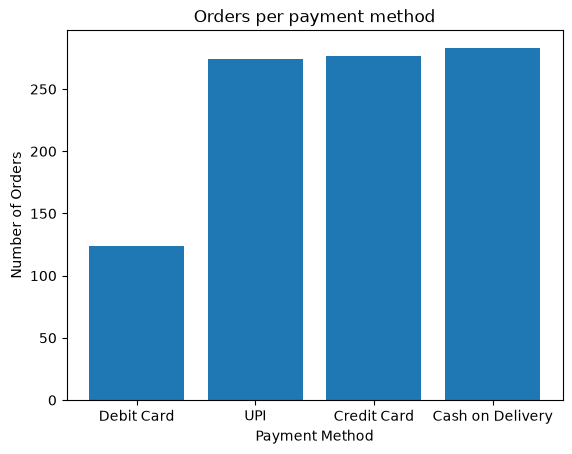

In [113]:
#Paymentmethod graph

plt.bar(Payment_method.index,Payment_method.values)
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.title("Orders per payment method")

<Axes: xlabel='category', ylabel='quantity'>

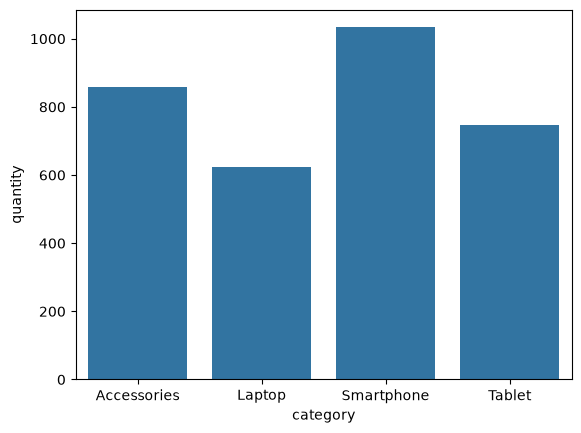

In [114]:
#Top Products graph

sea.barplot(top_products)

Text(0.5, 1.0, 'Quarterly Revenue')

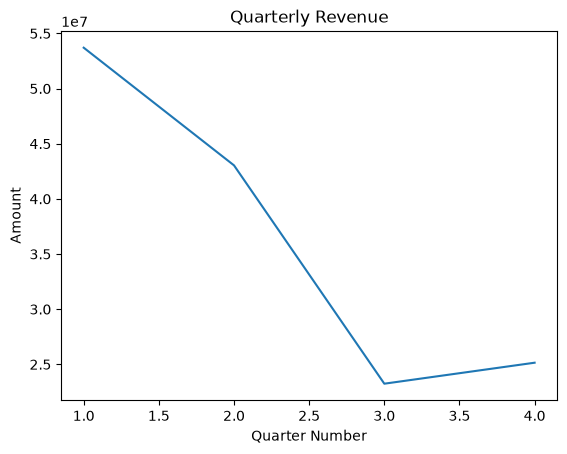

In [115]:
#Quarterly Revenue

plt.plot(quarterly_rev.sort_index().index,quarterly_rev.sort_index().values)
plt.xlabel("Quarter Number")
plt.ylabel("Amount")
plt.title("Quarterly Revenue")

Text(0.5, 1.0, 'Monthly Revenue')

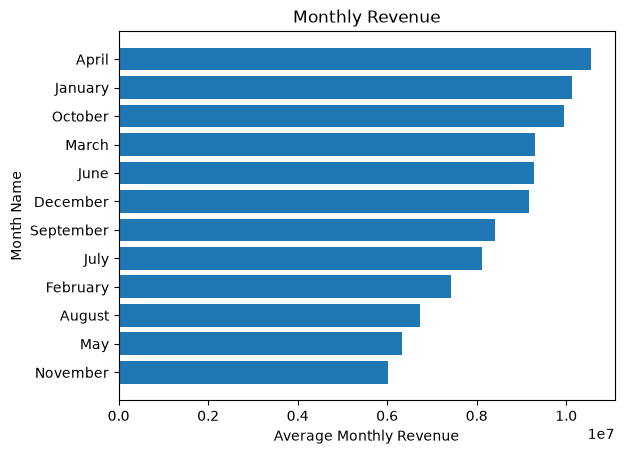

In [116]:
#Montly Revenue

plt.barh(monthly_rev.index,monthly_rev.values)
plt.ylabel("Month Name")
plt.xlabel("Average Monthly Revenue")
plt.title("Monthly Revenue")

Text(0.5, 1.0, 'Top Product Quantity sold')

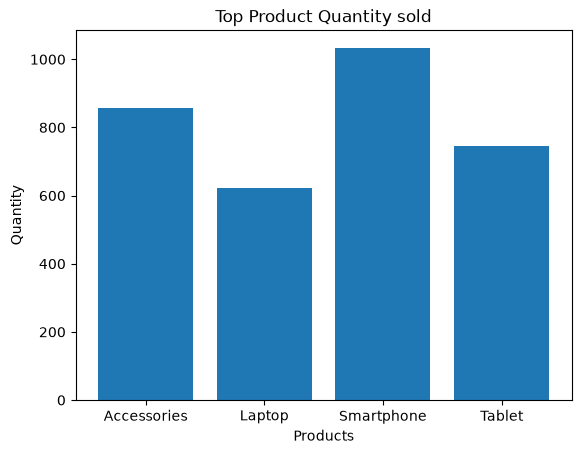

In [117]:
#Top products sold

plt.bar(top_products.index,top_products.values)
plt.xlabel("Products")
plt.ylabel("Quantity")
plt.title("Top Product Quantity sold")

Text(0.5, 1.0, 'City Wise Revenue Generated')

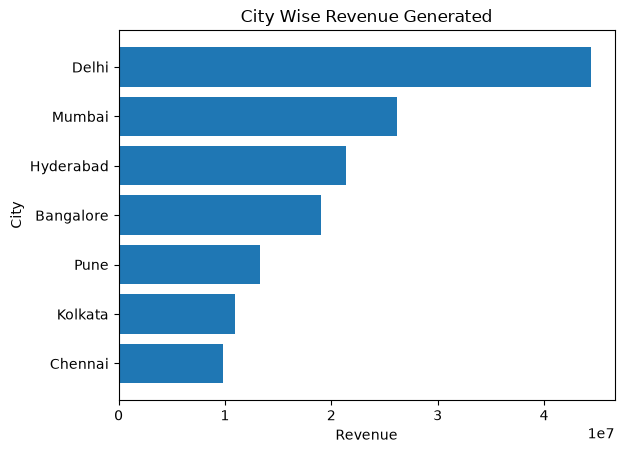

In [118]:
#Revenue generated by per city

plt.barh(City_wise_rev.index,City_wise_rev.values)
plt.xlabel("Revenue")
plt.ylabel("City")
plt.title("City Wise Revenue Generated")

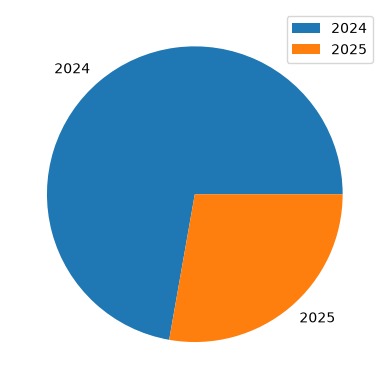

In [119]:
#Yearly Revenue

plt.pie(yearly_rev,labels=yearly_rev.index)
plt.legend()
plt.show()